In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [3]:

data = pd.read_csv(r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\data\raw\McDonald_s_Reviews.csv",encoding="latin1")
print(data.head(2))

   reviewer_id  store_name              category  \
0            1  McDonald's  Fast food restaurant   
1            2  McDonald's  Fast food restaurant   

                                       store_address  latitude   longitude  \
0  13749 US-183 Hwy, Austin, TX 78750, United States  30.460718 -97.792874   
1  13749 US-183 Hwy, Austin, TX 78750, United States  30.460718 -97.792874   

  rating_count   review_time  \
0        1,240  3 months ago   
1        1,240    5 days ago   

                                              review   rating  
0  Why does it look like someone spit on my food?...   1 star  
1  It'd McDonalds. It is what it is as far as the...  4 stars  


In [7]:
print(f"Data Shape : {data.shape}")
print("___________________________")
print(f"Data columns : {data.columns}")
print("___________________________")
print(f"Data info : {data.info()}")
print("___________________________")
print(f"Data describle : {data.describe()}")

Data Shape : (33396, 10)
___________________________
Data columns : Index(['reviewer_id', 'store_name', 'category', 'store_address', 'latitude ',
       'longitude', 'rating_count', 'review_time', 'review', 'rating'],
      dtype='str')
___________________________
<class 'pandas.DataFrame'>
RangeIndex: 33396 entries, 0 to 33395
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    33396 non-null  int64  
 1   store_name     33396 non-null  str    
 2   category       33396 non-null  str    
 3   store_address  33396 non-null  str    
 4   latitude       32736 non-null  float64
 5   longitude      32736 non-null  float64
 6   rating_count   33396 non-null  str    
 7   review_time    33396 non-null  str    
 8   review         33396 non-null  str    
 9   rating         33396 non-null  str    
dtypes: float64(2), int64(1), str(7)
memory usage: 10.2 MB
Data info : None
___________________________
Data 

In [5]:
for col in data.columns:
    print(col)
    print(data[col].isnull().sum())

reviewer_id
0
store_name
0
category
0
store_address
0
latitude 
660
longitude
660
rating_count
0
review_time
0
review
0
rating
0


In [6]:
for col in data.columns:
    print(col)
    print(data[col].duplicated().sum())

reviewer_id
0
store_name
33394
category
33395
store_address
33356
latitude 
33356
longitude
33356
rating_count
33345
review_time
33357
review
11111
rating
33391


In [8]:
data["rating"].value_counts()

rating
5 stars    10274
1 star      9431
4 stars     5787
3 stars     4818
2 stars     3086
Name: count, dtype: int64

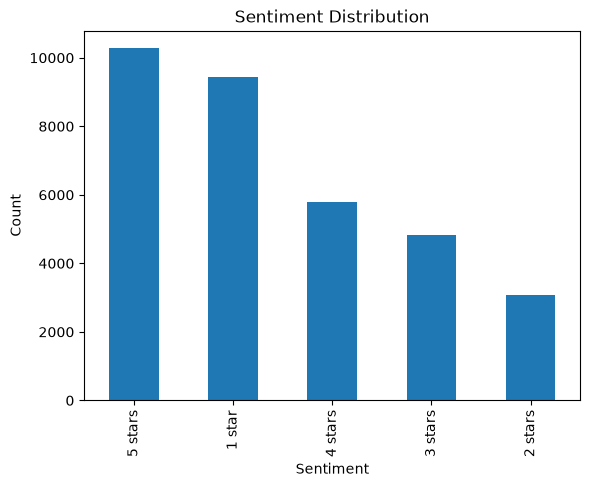

In [102]:
os.makedirs("report/EDA_Graph",exist_ok=True)
data["rating"].value_counts().plot(kind="bar")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.title("Sentiment Distribution")
plt.savefig("report/EDA_Graph/Sentiment_Distribution.png")
plt.show()

In [10]:
data["text_length"]=data["review"].astype(str).apply(len)

In [ ]:
data["text_length"].sort_values(ascending=False)

27955    3115
23021    3115
23689    2841
28803    2841
8680     2755
         ... 
1284        2
513         2
16915       2
18610       1
19669       1
Name: text_length, Length: 33396, dtype: int64

In [21]:
data["review"].iloc[0]

'Why does it look like someone spit on my food?\nI had a normal transaction,  everyone was chill and polite, but now i dont want to eat this. Im trying not to think about what this milky white/clear substance is all over my food, i d*** sure am not coming back.'

In [24]:
data["text_length"].describe()

count    33396.000000
mean       125.903042
std        184.000878
min          1.000000
25%         17.000000
50%         63.000000
75%        160.000000
max       3115.000000
Name: text_length, dtype: float64

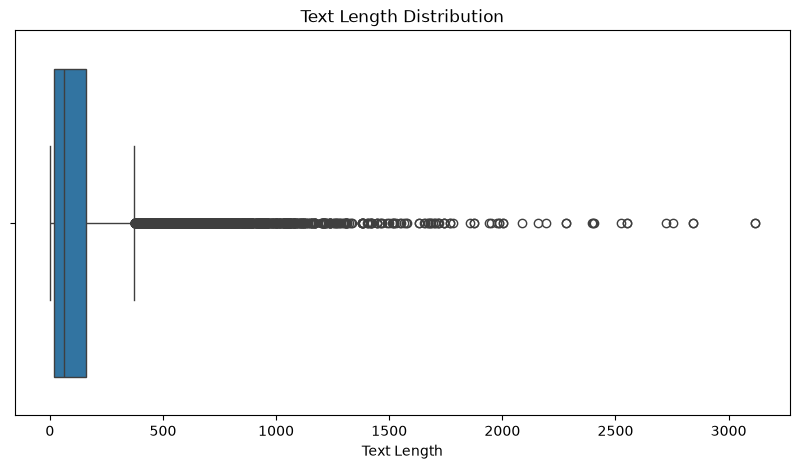

In [104]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=data["text_length"])

plt.title("Text Length Distribution")
plt.xlabel("Text Length")
plt.savefig(r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\report\EDA_Graph\Text_Length_distribution.png")
plt.show()

In [32]:
Q1 = data["text_length"].quantile(0.25)
Q3 = data["text_length"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier = data[(data["text_length"]>upper)|(data["text_length"]<lower)]
print(outlier)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower:", lower)
print("Upper:", upper)

       reviewer_id  store_name              category  \
2                3  McDonald's  Fast food restaurant   
6                7  McDonald's  Fast food restaurant   
9               10  McDonald's  Fast food restaurant   
12              13  McDonald's  Fast food restaurant   
18              19  McDonald's  Fast food restaurant   
...            ...         ...                   ...   
33247        33248  McDonald's  Fast food restaurant   
33250        33251  McDonald's  Fast food restaurant   
33263        33264  McDonald's  Fast food restaurant   
33266        33267  McDonald's  Fast food restaurant   
33278        33279  McDonald's  Fast food restaurant   

                                           store_address  latitude   \
2      13749 US-183 Hwy, Austin, TX 78750, United States  30.460718   
6      13749 US-183 Hwy, Austin, TX 78750, United States  30.460718   
9      13749 US-183 Hwy, Austin, TX 78750, United States  30.460718   
12     13749 US-183 Hwy, Austin, TX 78750, 

In [34]:
data[data["text_length"]>374].head(3)

,reviewer_id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating,text_length
2,3,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",5 days ago,Made a mobile order got to the speaker and che...,1 star,415
6,7,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,If I could give this location a zero on custo...,1 star,879
9,10,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,"I'm not really a huge fan of fast food, but I ...",4 stars,561


In [41]:
data[data["text_length"]==3115]["review"].iloc[0]

'I want to apologize to anyone that I recommended this particular McDonald\'s to in the past.\nThis was the restaurant that I used to recommend to tourists when they were looking for a fast place to eat that was away from the Disney parks, but still close enough to get back to the parks quickly. At that time, it was worth it. The menu was cheap (or at least what you know to expect from a international chain) and, since it\'s a chain, you know what the food is gong to be like.\nSo, let\'s look at what you need to do if you are a member of a chain of restaurants. You need to set yourself apart with your service. This WAS the reason I used to recommend this restaurant. Sadly, I don\'t think they care anymore. The last time we went, half of the kiosks weren\'t working. One of the three that was, didn\'t print receipts. (This plays a part into why the service was so atrocious. Actually there was a lot that played into it.) Now, if you\'ve gone to McDonald\'s at all recently, you know you pi

In [ ]:
data["text_length"].quantile([0.50, 0.75, 0.90, 0.95, 0.99])

0.50     63.0
0.75    160.0
0.90    315.0
0.95    453.0
0.99    882.0
Name: text_length, dtype: float64

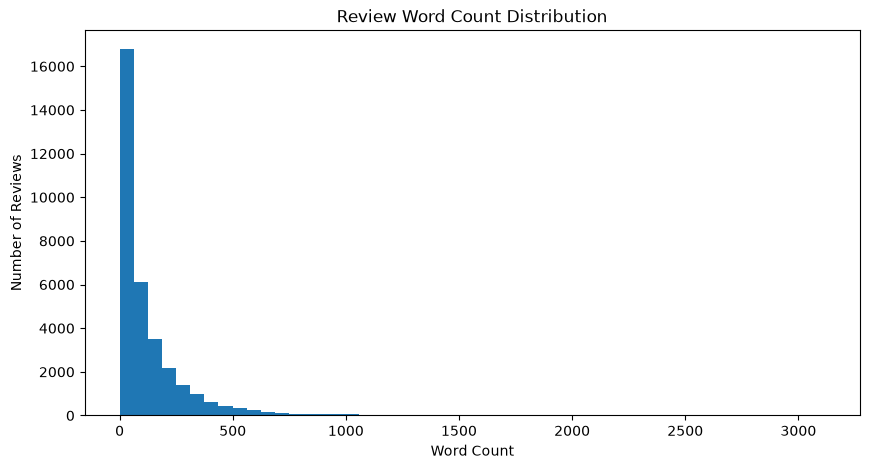

In [105]:
plt.figure(figsize=(10, 5))

plt.hist(data["text_length"], bins=50)

plt.xlabel("Word Count")
plt.ylabel("Number of Reviews")
plt.title("Review Word Count Distribution")
plt.savefig(r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\report\EDA_Graph\review_word_count_distribution.png")
plt.show()

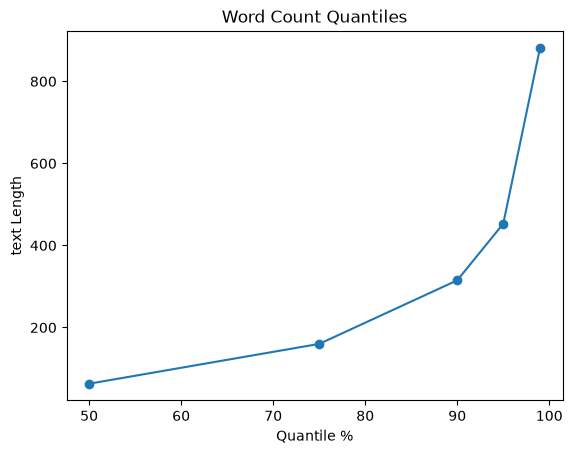

In [106]:
q = data["text_length"].quantile([0.50, 0.75, 0.90, 0.95, 0.99])

plt.plot(q.index * 100, q.values, marker="o")

plt.xlabel("Quantile %")
plt.ylabel("text Length")
plt.title("Word Count Quantiles")
plt.savefig(r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\report\EDA_Graph\word_count_Quentiles.png")
plt.show()

In [62]:
data.iloc[:,-1]

0        259
1        237
2        415
3        176
4        312
        ... 
33391     27
33392     24
33393     26
33394     51
33395     25
Name: text_length, Length: 33396, dtype: int64

In [74]:
data[data["text_length"]==1].iloc[0]


reviewer_id                                                  18611
store_name                                              McDonald's
category                                      Fast food restaurant
store_address    1100 N US Hwy 377, Roanoke, TX 76262, United S...
latitude                                                 33.009318
longitude                                               -97.222925
rating_count                                                   998
review_time                                            5 years ago
review                                                           K
rating                                                     4 stars
text_length                                                      1
Name: 18610, dtype: object

In [72]:
data[data["text_length"]==1].value_counts()

reviewer_id  store_name  category              store_address                                        latitude   longitude   rating_count  review_time  review  rating   text_length
18611        McDonald's  Fast food restaurant  1100 N US Hwy 377, Roanoke, TX 76262, United States  33.009318  -97.222925  998           5 years ago  K       4 stars  1              1
19670        McDonald's  Fast food restaurant  621 Broadway, Newark, NJ 07104, United States        40.771910  -74.161475  1,564         6 years ago  ?       2 stars  1              1
Name: count, dtype: int64

In [111]:
short_reviews=data[data["text_length"]>0].sort_values(by="text_length",ascending=True)[["review","text_length","rating"]].head(100)
print(short_reviews)


      review  text_length   rating
19669      ?            1  2 stars
18610      K            1  4 stars
33194     R4            2  3 stars
33197     Cc            2  3 stars
22019     Ok            2  4 stars
...      ...          ...      ...
15217     Ok            2  3 stars
6673      Ok            2  3 stars
2522      Ok            2  3 stars
8383      Ok            2  3 stars
8337      Ok            2  4 stars

[100 rows x 3 columns]


In [119]:
os.makedirs("report/EDA_Data", exist_ok=True)
short_reviews.to_csv(
    "C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\report\EDA_Data/short_reviews.csv",
    index=True
)

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (3005395532.py, line 3)

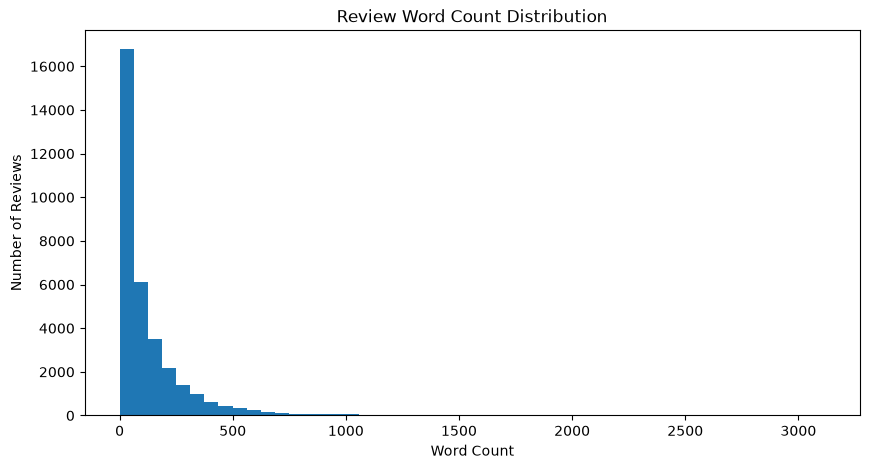

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(data["text_length"], bins=50)

plt.xlabel("Word Count")
plt.ylabel("Number of Reviews")
plt.title("Review Word Count Distribution")

plt.show()

In [88]:
short_reviews = data[data["text_length"] <= 2]

print(short_reviews[["review", "text_length", "rating"]])

      review  text_length   rating
467       Ok            2  3 stars
501       Ok            2  3 stars
502       Ok            2  4 stars
503       Ok            2  4 stars
513       Ok            2  2 stars
...      ...          ...      ...
33140     Ok            2  3 stars
33150     Ok            2  3 stars
33161     Ok            2  3 stars
33194     R4            2  3 stars
33197     Cc            2  3 stars

[100 rows x 3 columns]


In [93]:
data[
    (data["review"] == "?") |
    (data["review"] == "!!!") |
    (data["review"] == "@#$%")
]

,reviewer_id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating,text_length
19669,19670,McDonald's,Fast food restaurant,"621 Broadway, Newark, NJ 07104, United States",40.77191,-74.161475,"1,564",6 years ago,?,2 stars,1


In [97]:
data[
    (data["text_length"] == 0) ]

,reviewer_id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating,text_length


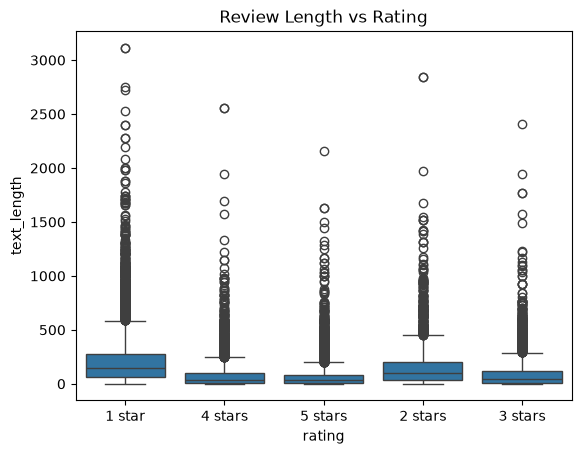

In [107]:
sns.boxplot(
    data=data,
    x="rating",
    y="text_length"
)

plt.title("Review Length vs Rating")
plt.savefig(r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\report\EDA_Graph\Review_Length_vs_Rating.png")
plt.show()

In [ ]:
#1.The dataset has more 5-star and 4-star #reviews, while 2-star and 3-star reviews are much lower. Therefore, the target classes are imbalanced.”

# Insight — Review Word Count
#Most reviews are short.
#Very few reviews are very long.
#The distribution is right-skewed.
#Maximum review length is around 3115 words.
#Minmum Review Length is 1 words
